In [1]:
import pandas as pd
import numpy as np

from sklearn.metrics import mean_absolute_percentage_error, r2_score
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import MinMaxScaler, PowerTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, StackingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

from xgboost import XGBRegressor
import lightgbm as lgb
from catboost import CatBoostRegressor

from sklearn.compose import TransformedTargetRegressor

import seaborn as sns
import matplotlib.pyplot as plt



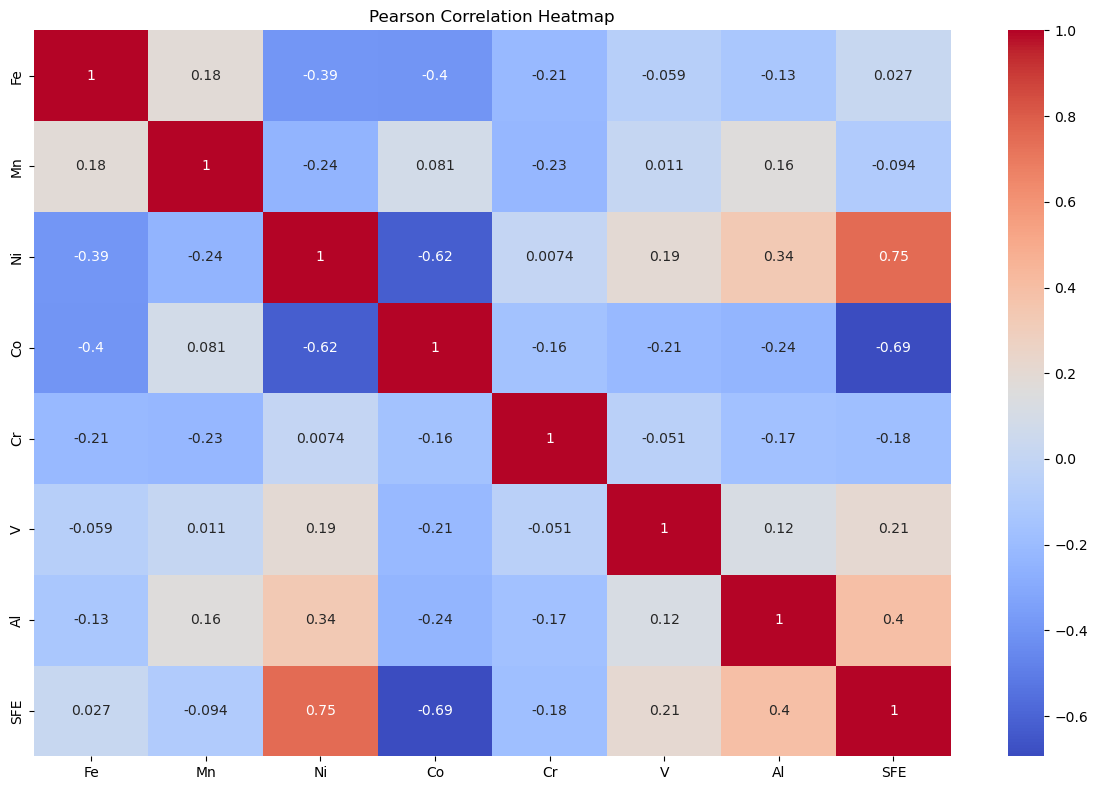

In [2]:
# ==========================
# 1. Load SFE dataset
# ==========================
df = pd.read_excel("Composition_SFE_Dataset_old.xlsx")  # adjust path if needed

# Input: compositions, Output: SFE (can be negative)
X = df.drop(columns=["SFE"])
y = df["SFE"]

# ==========================
# 2. Pearson correlation (no feature removal)
# ==========================
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="coolwarm")
plt.title("Pearson Correlation Heatmap")
plt.tight_layout()
plt.show()



In [3]:
# ==========================
# 3. Hyperparameter grids (with TransformedTargetRegressor -> regressor__)
# ==========================
def get_param_grid_for_model(model_name):
    param_grids = {
        'lr': {
            'model__regressor__fit_intercept': [True, False],
        },
        'ridge': {
            'model__regressor__alpha': [0.1, 1.0, 10.0],
            'model__regressor__fit_intercept': [True, False],
            'model__regressor__solver': [
                'auto', 'svd', 'cholesky', 'lsqr',
                'sparse_cg', 'sag', 'saga'
            ]
        },
        'lasso': {
            'model__regressor__alpha': [0.1, 1.0, 10.0],
            'model__regressor__fit_intercept': [True, False],
            'model__regressor__positive': [False],  # keep False, target can be negative
            'model__regressor__selection': ['cyclic', 'random']
        },
        'rf': {
            'model__regressor__n_estimators': [50, 100, 200],
            'model__regressor__max_depth': [None, 10, 20],
            'model__regressor__min_samples_split': [2, 5, 10],
            'model__regressor__min_samples_leaf': [1, 2, 4]
        },
        'gb': {
            'model__regressor__n_estimators': [50, 100, 200],
            'model__regressor__learning_rate': [0.01, 0.1, 0.2],
            'model__regressor__max_depth': [3, 5, 7],
            'model__regressor__min_samples_split': [2, 5, 10],
            'model__regressor__min_samples_leaf': [1, 2, 4]
        },
        'svr': {
            'model__regressor__C': [0.1, 1.0, 10.0],
            'model__regressor__kernel': ['linear', 'poly', 'rbf'],
            'model__regressor__gamma': ['scale', 'auto']
        },
        'knn': {
            'model__regressor__n_neighbors': [3, 5, 10],
            'model__regressor__weights': ['uniform', 'distance'],
            'model__regressor__algorithm': ['auto', 'ball_tree', 'kd_tree']
        },
        'dt': {
            'model__regressor__max_depth': [None, 5, 10, 20],
            'model__regressor__min_samples_split': [2, 5, 10],
            'model__regressor__min_samples_leaf': [1, 2, 4]
        },
        'xgb': {
            'model__regressor__n_estimators': [10, 50, 100],
            'model__regressor__learning_rate': [0.01, 0.1, 0.3],
            'model__regressor__max_depth': [3, 5],
            'model__regressor__gamma': [0, 0.1, 0.2],
            'model__regressor__reg_alpha': [0, 0.1, 0.5],
            'model__regressor__reg_lambda': [0, 1.0, 10.0],
        },
        'lgbm': {
            'model__regressor__n_estimators': [50, 100, 200],
            'model__regressor__learning_rate': [0.01, 0.1, 0.2],
            'model__regressor__max_depth': [3, 5, 7],
            'model__regressor__num_leaves': [31, 63],
            'model__regressor__min_child_samples': [20, 40],
            'model__regressor__subsample': [0.6, 0.8, 1.0],
            'model__regressor__colsample_bytree': [0.6, 0.8, 1.0]
        },
        'catboost': {
            'model__regressor__iterations': [100, 200, 500],
            'model__regressor__learning_rate': [0.01, 0.1, 0.2],
            'model__regressor__depth': [3, 5, 7]
        }
    }
    return param_grids.get(model_name, {})



In [4]:
# ==========================
# 4. Define models
# ==========================
models = {
    'lr': LinearRegression(),
    'ridge': Ridge(),
    'lasso': Lasso(),
    'rf': RandomForestRegressor(random_state=42),
    'gb': GradientBoostingRegressor(random_state=42),
    'svr': SVR(),
    'knn': KNeighborsRegressor(),
    'dt': DecisionTreeRegressor(random_state=42),
    'xgb': XGBRegressor(random_state=42, n_jobs=-1),
    'lgbm': lgb.LGBMRegressor(verbose=-1, random_state=42),
    'catboost': CatBoostRegressor(
        verbose=False,
        random_state=42,
        allow_writing_files=False  # avoid catboost_info dir issue
    )
}

# ==========================
# 5. Train-test split
# ==========================
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.1, random_state=42
)



In [6]:
# ==========================
# 6. Train individual models with GridSearchCV + PowerTransformer
# ==========================
best_models = {}

for name, model in models.items():
    print(f"Training model: {name}")

    # Pipeline: scale X, PowerTransform y via TTR
    pipeline = Pipeline([
        ('preprocessor', MinMaxScaler()),
        ('model', TransformedTargetRegressor(
            regressor=model,
            transformer=PowerTransformer()
        ))
    ])

    param_grid = get_param_grid_for_model(name)

    grid_search = GridSearchCV(
        pipeline,
        param_grid=param_grid,
        cv=3,
        scoring='neg_mean_squared_error',
        n_jobs=-1
    )
    grid_search.fit(X_train, y_train)

    best_models[name] = (grid_search.best_estimator_, grid_search.best_score_)

# ==========================
# 7. Select top-3 models for stacking
# ==========================
top_3_models = sorted(
    best_models.items(),
    key=lambda x: x[1][1],  # best_score_
    reverse=True
)[:3]

estimators = [(name, model) for name, (model, perf) in top_3_models]
print("Top 3 base models for stacking:", [e[0] for e in estimators])

# ==========================
# 8. Build stacked regressor with PowerTransformer on target
# ==========================
np.random.seed(42)

final_estimator = RandomForestRegressor(random_state=42)

final_estimator_param_grid = {
    'model__regressor__final_estimator__n_estimators': [50, 100, 200],
    'model__regressor__final_estimator__max_depth': [None, 10, 20],
    'model__regressor__final_estimator__min_samples_split': [2, 5, 10],
    'model__regressor__final_estimator__min_samples_leaf': [1, 2, 4]
}

stacked_regressor = StackingRegressor(
    estimators=estimators,
    final_estimator=final_estimator,
    passthrough=True,
    n_jobs=-1
)

stacked_model = Pipeline([
    ('preprocessor', MinMaxScaler()),
    ('model', TransformedTargetRegressor(
        regressor=stacked_regressor,
        transformer=PowerTransformer()
    ))
])

grid_search_stack = GridSearchCV(
    estimator=stacked_model,
    param_grid=final_estimator_param_grid,
    cv=5,
    scoring='neg_mean_squared_error',
    n_jobs=-1
)

grid_search_stack.fit(X_train, y_train)
stacked_model = grid_search_stack.best_estimator_

# ==========================
# 9. Evaluate stacked model
# ==========================
y_test_pred = stacked_model.predict(X_test)
y_train_pred = stacked_model.predict(X_train)
y_total_pred = stacked_model.predict(X)



Training model: lr


Exception in thread ExecutorManagerThread:
Traceback (most recent call last):
  File "C:\Users\DEBS\anaconda3\envs\sfe_ml\lib\site-packages\psutil\_pswindows.py", line 692, in wrapper
    return fun(self, *args, **kwargs)
  File "C:\Users\DEBS\anaconda3\envs\sfe_ml\lib\site-packages\psutil\_pswindows.py", line 870, in kill
    return cext.proc_kill(self.pid)
PermissionError: [WinError 5] Access is denied: '(originated from OpenProcess)'

The above exception was the direct cause of the following exception:

Traceback (most recent call last):
  File "C:\Users\DEBS\anaconda3\envs\sfe_ml\lib\threading.py", line 1016, in _bootstrap_inner
    self.run()
  File "C:\Users\DEBS\anaconda3\envs\sfe_ml\lib\site-packages\joblib\externals\loky\process_executor.py", line 626, in run
    self.terminate_broken(bpe)
  File "C:\Users\DEBS\anaconda3\envs\sfe_ml\lib\site-packages\joblib\externals\loky\process_executor.py", line 833, in terminate_broken
    self.kill_workers(reason="broken executor")
  File

TerminatedWorkerError: A worker process managed by the executor was unexpectedly terminated. This could be caused by a segmentation fault while calling the function or by an excessive memory usage causing the Operating System to kill the worker.

Detailed tracebacks of the workers should have been printed to stderr in the executor process if faulthandler was not disabled.

In [6]:
print("\nStacked Model Performance:")
print("Train R2:", r2_score(y_train, y_train_pred))
print("Test R2:", r2_score(y_test, y_test_pred))
print("Overall R2:", r2_score(y, y_total_pred))
print("Train MAPE:", mean_absolute_percentage_error(y_train, y_train_pred))
print("Test MAPE:", mean_absolute_percentage_error(y_test, y_test_pred))
print("Overall MAPE:", mean_absolute_percentage_error(y, y_total_pred))

# ==========================
# 10. Compare individual model performance in a table
# ==========================
model_performance_df = pd.DataFrame(
    columns=[
        "Model Name", "Train R2", "Test R2", "Overall R2",
        "Train MAPE", "Test MAPE", "Overall MAPE", "Error Variance"
    ]
)

model_namer = {
    "lr": "Linear Regression",
    "ridge": "Ridge Regression",
    "lasso": "Lasso Regression",
    "rf": "Random Forest",
    "gb": "Gradient Boosting",
    "svr": "Support Vector Regressor",
    "knn": "K-Nearest Neighbors",
    "dt": "Decision Tree",
    "xgb": "XGBoost",
    "lgbm": "LightGBM",
    "catboost": "CatBoost"
}




Stacked Model Performance:
Train R2: 0.9946412640232747
Test R2: 0.8833808800266684
Overall R2: 0.9807168264617651
Train MAPE: 0.16494188902873738
Test MAPE: 0.3956642209578801
Overall MAPE: 0.18823076290890906


In [7]:
# Base models
for model_name, (best_estimator, _) in best_models.items():

    y_pred_train = best_estimator.predict(X_train)
    y_pred_test = best_estimator.predict(X_test)
    y_pred_total = best_estimator.predict(X)

    error = y_pred_total - y

    model_performance_df = pd.concat(
        [model_performance_df,
         pd.DataFrame([{
             "Model Name": model_namer.get(model_name, model_name),
             "Train R2": r2_score(y_train, y_pred_train),
             "Test R2": r2_score(y_test, y_pred_test),
             "Overall R2": r2_score(y, y_pred_total),
             "Train MAPE": mean_absolute_percentage_error(y_train, y_pred_train),
             "Test MAPE": mean_absolute_percentage_error(y_test, y_pred_test),
             "Overall MAPE": mean_absolute_percentage_error(y, y_pred_total),
             "Error Variance": error.var()
         }])],
        ignore_index=True
    )



C:\Users\DEBS\AppData\Local\Temp\ipykernel_10228\2042433515.py:10: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  model_performance_df = pd.concat(


In [8]:
# Stacked model row
error_stacked = y_total_pred - y

model_performance_df = pd.concat(
    [model_performance_df,
     pd.DataFrame([{
         "Model Name": "Stacked Model",
         "Train R2": r2_score(y_train, y_train_pred),
         "Test R2": r2_score(y_test, y_test_pred),
         "Overall R2": r2_score(y, y_total_pred),
         "Train MAPE": mean_absolute_percentage_error(y_train, y_train_pred),
         "Test MAPE": mean_absolute_percentage_error(y_test, y_test_pred),
         "Overall MAPE": mean_absolute_percentage_error(y, y_total_pred),
         "Error Variance": error_stacked.var()
     }])],
    ignore_index=True
)



In [9]:
model_performance_df = model_performance_df.sort_values(by="Test R2", ascending=False)

print("\n========================")
print(" FULL MODEL PERFORMANCE ")
#========================\n")
print(model_performance_df)



 FULL MODEL PERFORMANCE 
                  Model Name  Train R2   Test R2  Overall R2  Train MAPE  \
5   Support Vector Regressor  0.987453  0.947841    0.982545    0.257752   
6        K-Nearest Neighbors  0.999601  0.904281    0.987652    0.014791   
11             Stacked Model  0.994641  0.883381    0.980717    0.164942   
10                  CatBoost  0.998836  0.843163    0.979324    0.093183   
3              Random Forest  0.984066  0.751186    0.954943    0.162111   
4          Gradient Boosting  0.998795  0.619596    0.951258    0.089818   
8                    XGBoost  0.999170  0.611564    0.950578    0.074976   
9                   LightGBM  0.972119  0.521425    0.915743    0.252990   
1           Ridge Regression  0.767810  0.369448    0.718943    0.749018   
0          Linear Regression  0.769900  0.348193    0.718084    0.781546   
2           Lasso Regression  0.373985  0.179101    0.352458    1.296207   
7              Decision Tree  0.966126  0.174189    0.866994  

In [10]:
#

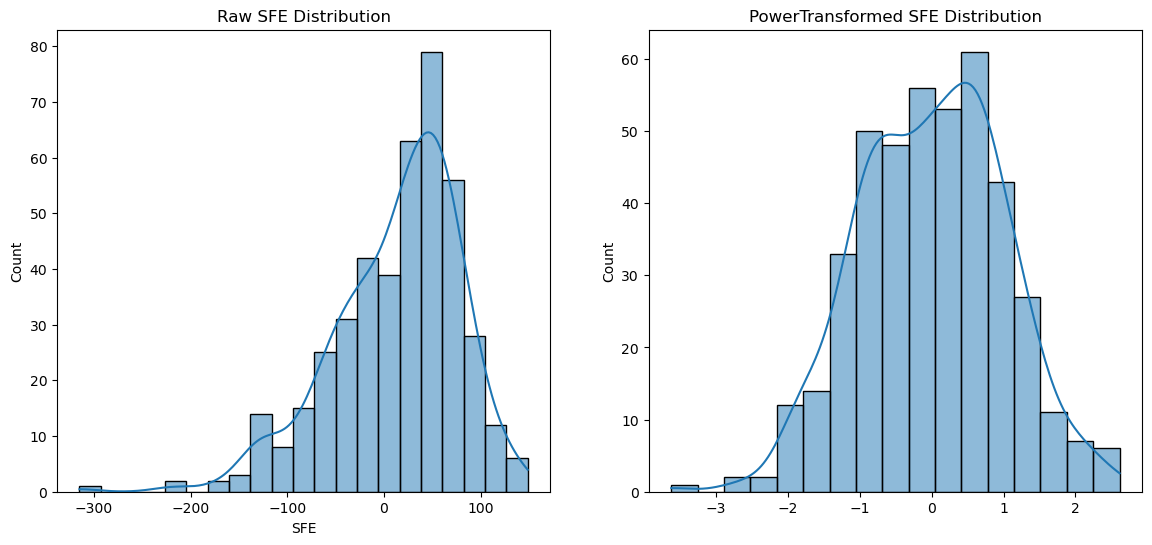

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PowerTransformer

pt = PowerTransformer()
y_pt = pt.fit_transform(y.values.reshape(-1,1)).flatten()

plt.figure(figsize=(14,6))

plt.subplot(1,2,1)
sns.histplot(y, kde=True)
plt.title("Raw SFE Distribution")

plt.subplot(1,2,2)
sns.histplot(y_pt, kde=True)
plt.title("PowerTransformed SFE Distribution")

plt.show()


In [12]:
import joblib

# Replace `stacked_model` with the actual variable name of your best estimator
joblib.dump(stacked_model, "stacked_sfe_model.pkl")

print("Model saved successfully!")


Model saved successfully!


In [13]:
import joblib

# Replace `stacked_model` with the actual variable name of your best estimator
joblib.dump(stacked_model, "stacked_sfe_model.pkl")

print("Model saved successfully!")


Model saved successfully!


In [14]:
import sys
!{sys.executable} -m pip install shap
